# Pan African Resources (JSE: PAN) -- 2-Year Analyst Forecast & JSE Valuation Sandbox
**Primary Listing**: Johannesburg Stock Exchange (JSE: PAN) | **Secondary**: AIM (PAF) | **Primary Currency**: ZAR (Rands)
**Forecast Horizon**: FY27E & FY28E | **Spot Exchange Rate**: ~16.50 USD/ZAR

Welcome to your interactive JSE valuation sandbox! This notebook allows you to:
1. **Tweak Macro Assumptions**: Realized gold prices ($/oz), USD/ZAR & USD/AUD rates, formula tax rates, and solar fleet savings.
2. **Inspect Real-Time Financials**: Consolidated P&L, Capex Cliff ($224m -> $110m -> $65m), FCFE surge, and net cash accumulation.
3. **Evaluate Trading Multiples**: EV/EBITDA compression (2.01x in FY27, 1.13x in FY28), P/E, FCF yield (25.3% / 34.1%), and **12-month JSE target price in ZAR**.
4. **Visualize Sensitivities**: Capex cliff inflection chart and 2D target price heatmaps across Gold Price x USD/ZAR in **Rands per share**.

> **Thin Notebook Architecture**: All deterministic financial logic, bottom-up asset projections, and verified FY26 baseline data live in `companies.PAN.models`.
> Run each cell sequentially. Adjust inputs in **Cell 2** to test your own scenarios.


In [1]:
# Enable inline plotting for VS Code Jupyter Notebooks
%matplotlib inline

import sys
from pathlib import Path

# Ensure project root is in sys.path for clean module imports
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parents[2] if 'companies' in NOTEBOOK_DIR.parts else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

try:
    from IPython.display import display
except ImportError:
    display = print

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['font.size'] = 10

from companies.PAN.models.data_loader import load_fy26_baseline
from companies.PAN.models.macro_deck import MacroDeck, Scenario, YearMacro
from companies.PAN.models.two_year_model import TwoYearModel, ConsolidatedForecast
from companies.PAN.models.multiples_valuation import ValuationEngine

# Load verified FY26 actuals from SQLite database
baseline = load_fy26_baseline()
print(f"[+] Loaded FY26 baseline for {baseline.company_name} ({baseline.ticker})")
print(f"  * FY26 Gold Sold: {baseline.total_gold_sold_oz:,.0f} oz at ${baseline.avg_gold_price_usd_per_oz:,.0f}/oz")
print(f"  * FY26 Adjusted EBITDA: ${baseline.group_adjusted_ebitda_usdm:,.1f}m")
print(f"  * FY26 Capex: ${baseline.capital_expenditure_usdm:,.1f}m (Capex Peak)")
print(f"  * Closing Net Cash: ${-baseline.net_debt_usdm:,.1f}m | Diluted Shares: {baseline.shares_in_issue_diluted_m:,.1f}m")


[+] Loaded FY26 baseline for Pan African Resources PLC (PAN)
  * FY26 Gold Sold: 272,373 oz at $4,235/oz
  * FY26 Adjusted EBITDA: $609.4m
  * FY26 Capex: $224.0m (Capex Peak)
  * Closing Net Cash: $185.6m | Diluted Shares: 2,027.3m


In [2]:
# ==============================================================================
# [CONTROLS] INTERACTIVE ANALYST CONTROLS -- ADJUST YOUR ASSUMPTIONS HERE
# ==============================================================================

# 1. Macro Scenario Preset
# Options: 'base' ($5,050 / $5,750), 'bear' ($3,750 / $4,300), 'bull' ($5,500 / $7,000), or 'custom'
ACTIVE_PRESET = 'base'  

# 2. Custom Gold Price Targets (USD / oz) -- active if ACTIVE_PRESET == 'custom'
CUSTOM_FY27_GOLD_PRICE = 5050.0   # Institutional Base Case
CUSTOM_FY28_GOLD_PRICE = 5750.0   # Institutional Base Case

# 3. Currency Assumptions
CUSTOM_USD_ZAR = 16.50            # Spot exchange rate ~16.49
CUSTOM_USD_AUD = 1.44             # Australian Dollar per USD (~0.694 USD/AUD)

# 4. Cash Tax Transition Rate (Section 36 formula tax run-down)
CUSTOM_FY27_CASH_TAX_RATE = 0.208 # 20.8% blended cash tax
CUSTOM_FY28_CASH_TAX_RATE = 0.275 # 27.5% blended cash tax

# 5. Behind-The-Meter Solar Fleet Net Power Savings ($m / year)
CUSTOM_FY27_SOLAR_SAVINGS = 12.5  # Fairview 8.75MW + Elikhulu 9.99MW ramp
CUSTOM_FY28_SOLAR_SAVINGS = 18.5  # Full fleet operational savings

# 6. Target Valuation Multiple (1-Year Forward EV / EBITDA)
TARGET_EV_EBITDA_MULTIPLE = 3.5   # Mid-tier peer benchmark (range 3.0x - 4.5x)

# ==============================================================================
# Build Macro Deck
if ACTIVE_PRESET in ('base', 'bull', 'bear'):
    macro_deck = MacroDeck.create(Scenario(ACTIVE_PRESET))
    print(f"[+] Loaded '{ACTIVE_PRESET.upper()}' Macro Preset:")
    print(f"  * FY27E: Gold ${macro_deck.fy27.gold_price_usd_per_oz:,.0f}/oz | USD/ZAR {macro_deck.fy27.usd_zar_rate:.2f} | Cash Tax {macro_deck.fy27.cash_tax_rate*100:.1f}%")
    print(f"  * FY28E: Gold ${macro_deck.fy28.gold_price_usd_per_oz:,.0f}/oz | USD/ZAR {macro_deck.fy28.usd_zar_rate:.2f} | Cash Tax {macro_deck.fy28.cash_tax_rate*100:.1f}%")
else:
    macro_deck = MacroDeck(
        scenario=Scenario.BASE,
        fy27=YearMacro(
            fiscal_year='FY27E',
            gold_price_usd_per_oz=CUSTOM_FY27_GOLD_PRICE,
            usd_zar_rate=CUSTOM_USD_ZAR,
            usd_aud_rate=CUSTOM_USD_AUD,
            cash_tax_rate=CUSTOM_FY27_CASH_TAX_RATE,
            solar_savings_usdm=CUSTOM_FY27_SOLAR_SAVINGS,
            cost_inflation_pct=0.055,
        ),
        fy28=YearMacro(
            fiscal_year='FY28E',
            gold_price_usd_per_oz=CUSTOM_FY28_GOLD_PRICE,
            usd_zar_rate=CUSTOM_USD_ZAR,
            usd_aud_rate=CUSTOM_USD_AUD,
            cash_tax_rate=CUSTOM_FY28_CASH_TAX_RATE,
            solar_savings_usdm=CUSTOM_FY28_SOLAR_SAVINGS,
            cost_inflation_pct=0.050,
        ),
    )
    print("[+] Configured CUSTOM Macro Scenario.")


[+] Loaded 'BASE' Macro Preset:
  * FY27E: Gold $5,050/oz | USD/ZAR 16.50 | Cash Tax 20.8%
  * FY28E: Gold $5,750/oz | USD/ZAR 16.50 | Cash Tax 27.5%


In [3]:
# Run 2-Year Forecast Model & Valuation Engine
model = TwoYearModel(baseline=baseline, macro_deck=macro_deck)
forecast = model.run()
valuation = ValuationEngine(forecast=forecast).evaluate(target_ev_ebitda=TARGET_EV_EBITDA_MULTIPLE)

# Construct Consolidated Summary DataFrame
df_financials = pd.DataFrame({
    'Metric (USD millions)': [
        'Gold Sold (oz)',
        'Realized Gold Price ($/oz)',
        'Revenue ($m)',
        'Cost of Production ($m)',
        'Adjusted EBITDA ($m)',
        'EBITDA Margin (%)',
        'Headline Earnings ($m)',
        'HEPS (US cents)',
        'HEPS (ZAR cents)',
        'HEPS (GB pence)',
        'Operating Cash Flow ($m)',
        'Total Capital Expenditure ($m)',
        '  - Sustaining Capex ($m)',
        '  - Expansion Capex ($m)',
        'Free Cash Flow to Equity (FCFE) ($m)',
        'Dividends Paid (40% payout) ($m)',
        'Closing Net Cash ($m)',
    ],
    'FY26 Actual': [
        f"{baseline.total_gold_sold_oz:,.0f}",
        f"${baseline.avg_gold_price_usd_per_oz:,.0f}",
        f"${baseline.revenue_usdm:,.1f}",
        f"-${baseline.cost_of_production_usdm:,.1f}",
        f"${baseline.group_adjusted_ebitda_usdm:,.1f}",
        f"{(baseline.group_adjusted_ebitda_usdm / baseline.revenue_usdm * 100):.1f}%",
        f"${baseline.headline_earnings_usdm:,.1f}",
        f"{(baseline.headline_eps_zar_cents / baseline.avg_exchange_rate_usd_zar):.2f}c",
        f"{baseline.headline_eps_zar_cents:.1f}c",
        f"{(baseline.headline_eps_zar_cents / baseline.avg_exchange_rate_usd_zar * 0.765):.2f}p",
        f"${baseline.cash_generated_from_operations_usdm:,.1f}",
        f"-${baseline.capital_expenditure_usdm:,.1f}",
        f"-${baseline.sustaining_capital_usdm:,.1f}",
        f"-${(baseline.capital_expenditure_usdm - baseline.sustaining_capital_usdm):.1f}",
        f"${baseline.levered_free_cash_flow_usdm:,.1f}",
        f"-${baseline.dividends_paid_cash_usdm:,.1f}",
        f"${-baseline.net_debt_usdm:,.1f}",
    ],
    'FY27 Forecast': [
        f"{forecast.fy27.gold_sold_oz:,.0f}",
        f"${forecast.fy27.macro.gold_price_usd_per_oz:,.0f}",
        f"${forecast.fy27.revenue_usdm:,.1f}",
        f"-${forecast.fy27.cost_of_production_usdm:,.1f}",
        f"${forecast.fy27.adjusted_ebitda_usdm:,.1f}",
        f"{(forecast.fy27.adjusted_ebitda_usdm / forecast.fy27.revenue_usdm * 100):.1f}%",
        f"${forecast.fy27.headline_earnings_usdm:,.1f}",
        f"{forecast.fy27.heps_usd_cents:.2f}c",
        f"{forecast.fy27.heps_zar_cents:.1f}c",
        f"{forecast.fy27.heps_gb_pence:.2f}p",
        f"${forecast.fy27.operating_cash_flow_usdm:,.1f}",
        f"-${forecast.fy27.total_capex_usdm:,.1f}",
        f"-${forecast.fy27.sustaining_capex_usdm:,.1f}",
        f"-${forecast.fy27.expansion_capex_usdm:,.1f}",
        f"${forecast.fy27.free_cash_flow_to_equity_usdm:,.1f}",
        f"-${forecast.fy27.dividend_payment_usdm:,.1f}",
        f"${forecast.fy27.closing_net_cash_usdm:,.1f}",
    ],
    'FY28 Forecast': [
        f"{forecast.fy28.gold_sold_oz:,.0f}",
        f"${forecast.fy28.macro.gold_price_usd_per_oz:,.0f}",
        f"${forecast.fy28.revenue_usdm:,.1f}",
        f"-${forecast.fy28.cost_of_production_usdm:,.1f}",
        f"${forecast.fy28.adjusted_ebitda_usdm:,.1f}",
        f"{(forecast.fy28.adjusted_ebitda_usdm / forecast.fy28.revenue_usdm * 100):.1f}%",
        f"${forecast.fy28.headline_earnings_usdm:,.1f}",
        f"{forecast.fy28.heps_usd_cents:.2f}c",
        f"{forecast.fy28.heps_zar_cents:.1f}c",
        f"{forecast.fy28.heps_gb_pence:.2f}p",
        f"${forecast.fy28.operating_cash_flow_usdm:,.1f}",
        f"-${forecast.fy28.total_capex_usdm:,.1f}",
        f"-${forecast.fy28.sustaining_capex_usdm:,.1f}",
        f"-${forecast.fy28.expansion_capex_usdm:,.1f}",
        f"${forecast.fy28.free_cash_flow_to_equity_usdm:,.1f}",
        f"-${forecast.fy28.dividend_payment_usdm:,.1f}",
        f"${forecast.fy28.closing_net_cash_usdm:,.1f}",
    ]
})

display(df_financials.set_index('Metric (USD millions)'))


,FY26 Actual,FY27 Forecast,FY28 Forecast
Metric (USD millions),,,
Gold Sold (oz),"272,373","300,000","322,000"
Realized Gold Price ($/oz),"$4,235","$5,050","$5,750"
Revenue ($m),"$1,156.5","$1,515.0","$1,851.5"
Cost of Production ($m),-$514.3,-$453.8,-$480.1
Adjusted EBITDA ($m),$609.4,$979.0,"$1,275.9"
EBITDA Margin (%),52.7%,64.6%,68.9%
Headline Earnings ($m),$358.0,$724.2,$887.2
HEPS (US cents),17.64c,35.72c,43.76c
HEPS (ZAR cents),298.1c,589.4c,722.0c


In [4]:
# Valuation Multiples Table (Prioritizing JSE ZAR Trading)
df_multiples = pd.DataFrame({
    'Valuation Metric': [
        'JSE Share Price (ZAR)',
        'Share Price (USD)',
        'Market Capitalization ($m)',
        'Net Cash / (Debt) ($m)',
        'Enterprise Value ($m)',
        'EV / Adjusted EBITDA',
        'Price / Headline Earnings (P/E)',
        'Free Cash Flow Yield (%)',
        'Dividend Yield (%)',
    ],
    'FY26 Actual': [
        f"R{valuation.fy26_actual.share_price_zar:.2f}",
        f"${valuation.fy26_actual.share_price_usd:.3f}",
        f"${valuation.fy26_actual.market_cap_usdm:,.1f}m",
        f"${valuation.fy26_actual.net_cash_usdm:,.1f}m",
        f"${valuation.fy26_actual.enterprise_value_usdm:,.1f}m",
        f"{valuation.fy26_actual.ev_to_ebitda:.2f}x",
        f"{valuation.fy26_actual.price_to_earnings_heps:.2f}x",
        f"{valuation.fy26_actual.free_cash_flow_yield_pct:.1f}%",
        f"{valuation.fy26_actual.dividend_yield_pct:.1f}%",
    ],
    'FY27E (1-Yr Forward)': [
        f"R{valuation.fy27_forward.share_price_zar:.2f}",
        f"${valuation.fy27_forward.share_price_usd:.3f}",
        f"${valuation.fy27_forward.market_cap_usdm:,.1f}m",
        f"${valuation.fy27_forward.net_cash_usdm:,.1f}m",
        f"${valuation.fy27_forward.enterprise_value_usdm:,.1f}m",
        f"{valuation.fy27_forward.ev_to_ebitda:.2f}x",
        f"{valuation.fy27_forward.price_to_earnings_heps:.2f}x",
        f"{valuation.fy27_forward.free_cash_flow_yield_pct:.1f}%",
        f"{valuation.fy27_forward.dividend_yield_pct:.1f}%",
    ],
    'FY28E (2-Yr Forward)': [
        f"R{valuation.fy28_forward.share_price_zar:.2f}",
        f"${valuation.fy28_forward.share_price_usd:.3f}",
        f"${valuation.fy28_forward.market_cap_usdm:,.1f}m",
        f"${valuation.fy28_forward.net_cash_usdm:,.1f}m",
        f"${valuation.fy28_forward.enterprise_value_usdm:,.1f}m",
        f"{valuation.fy28_forward.ev_to_ebitda:.2f}x",
        f"{valuation.fy28_forward.price_to_earnings_heps:.2f}x",
        f"{valuation.fy28_forward.free_cash_flow_yield_pct:.1f}%",
        f"{valuation.fy28_forward.dividend_yield_pct:.1f}%",
    ]
})

print(f"[TARGET] 12-MONTH JSE TARGET PRICE (Target EV/EBITDA: {TARGET_EV_EBITDA_MULTIPLE:.1f}x):")
print(f"   * JSE Target Price: ZAR {valuation.target_price_12m_zar:.2f} (R{valuation.target_price_12m_zar:.2f} / share)")
print(f"   * Current JSE Price: ZAR {valuation.fy26_actual.share_price_zar:.2f} (R{valuation.fy26_actual.share_price_zar:.2f} / share)")
print(f"   * Implied JSE Capital Upside: +{valuation.implied_upside_pct:.1f}%")
print(f"   * Cross-Border Equivalent: US$ {valuation.target_price_12m_usd:.2f} / {valuation.target_price_12m_gb_pence:.1f}p (AIM)")

display(df_multiples.set_index('Valuation Metric'))


[TARGET] 12-MONTH JSE TARGET PRICE (Target EV/EBITDA: 3.5x):
   * JSE Target Price: ZAR 32.51 (R32.51 / share)
   * Current JSE Price: ZAR 20.59 (R20.59 / share)
   * Implied JSE Capital Upside: +57.5%
   * Cross-Border Equivalent: US$ 1.97 / 150.4p (AIM)


,FY26 Actual,FY27E (1-Yr Forward),FY28E (2-Yr Forward)
Valuation Metric,,,
JSE Share Price (ZAR),R20.59,R20.64,R20.64
Share Price (USD),$1.251,$1.251,$1.251
Market Capitalization ($m),"$2,535.9m","$2,535.9m","$2,535.9m"
Net Cash / (Debt) ($m),$185.6m,$570.8m,"$1,090.2m"
Enterprise Value ($m),"$2,350.3m","$1,965.1m","$1,445.7m"
EV / Adjusted EBITDA,3.86x,2.01x,1.13x
Price / Headline Earnings (P/E),7.09x,3.50x,2.86x
Free Cash Flow Yield (%),8.0%,25.3%,34.1%
Dividend Yield (%),2.3%,10.1%,13.7%


In [5]:
# Bottom-Up Asset Projections
asset_rows = []
for key, a27 in forecast.fy27.assets.items():
    a28 = forecast.fy28.assets[key]
    asset_rows.append({
        'Mining Asset': a27.name,
        'FY27 Prod (oz)': f"{a27.gold_sold_oz:,.0f}",
        'FY27 Cash Cost ($/oz)': f"${a27.cash_cost_usd_per_oz:,.0f}",
        'FY27 AISC ($/oz)': f"${a27.aisc_usd_per_oz:,.0f}",
        'FY27 Capex ($m)': f"${a27.total_capex_usdm:.1f}m",
        'FY27 EBITDA ($m)': f"${a27.adjusted_ebitda_usdm:.1f}m",
        'FY28 Prod (oz)': f"{a28.gold_sold_oz:,.0f}",
        'FY28 AISC ($/oz)': f"${a28.aisc_usd_per_oz:,.0f}",
        'FY28 Capex ($m)': f"${a28.total_capex_usdm:.1f}m",
        'FY28 EBITDA ($m)': f"${a28.adjusted_ebitda_usdm:.1f}m",
    })

df_assets = pd.DataFrame(asset_rows).set_index('Mining Asset')
display(df_assets)


,FY27 Prod (oz),FY27 Cash Cost ($/oz),FY27 AISC ($/oz),FY27 Capex ($m),FY27 EBITDA ($m),FY28 Prod (oz),FY28 AISC ($/oz),FY28 Capex ($m),FY28 EBITDA ($m)
Mining Asset,,,,,,,,,
"Barberton Underground (Fairview, Sheba, Consort)","72,000","$2,166","$2,620",$31.5m,$204.4m,"75,000","$2,650",$24.0m,$262.0m
Barberton Tailings Retreatment Plant (BTRP),"20,000","$1,420","$1,480",$7.5m,$71.7m,"30,000","$1,450",$6.0m,$129.8m
Evander Underground (8 Shaft 24-26 Level),"44,000","$1,720","$1,750",$30.0m,$144.5m,"46,000","$1,740",$14.5m,$184.2m
Elikhulu Tailings Retreatment Plant,"56,000","$1,111","$1,240",$7.0m,$218.1m,"56,000","$1,250",$2.5m,$256.8m
Mogale Tailings Retreatment (MTR Operation),"63,000","$1,180","$1,320",$8.5m,$241.0m,"65,000","$1,300",$4.0m,$295.4m
Tennant Mines (Nobles CIL Hub),"45,000","$1,550","$2,150",$18.5m,$155.5m,"50,000","$2,100",$7.0m,$210.2m


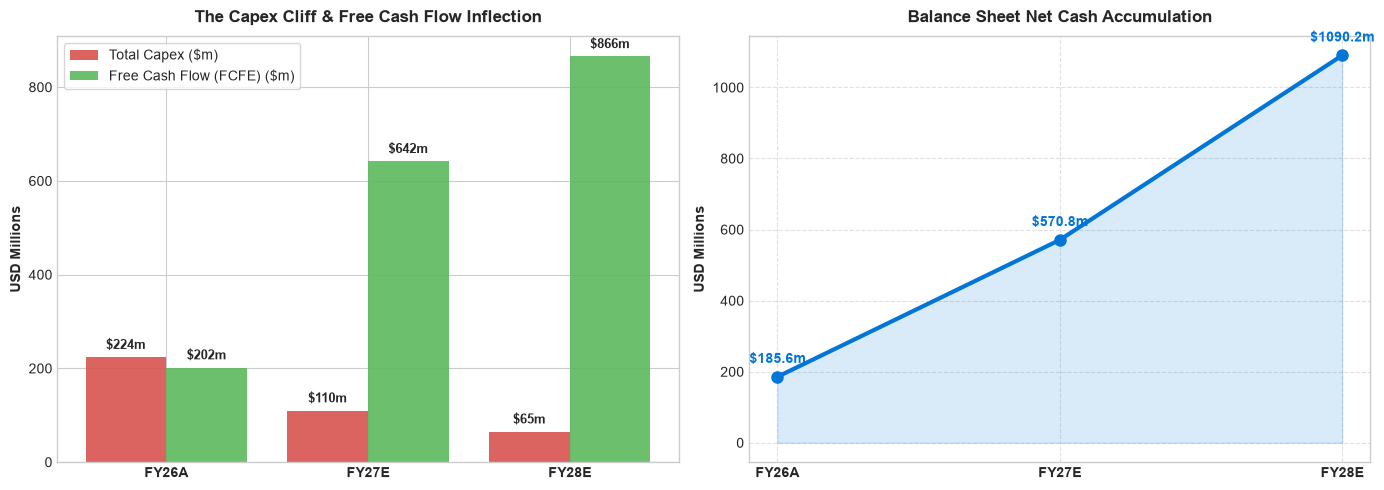

In [6]:
# Enable inline plotting for VS Code
%matplotlib inline

# Visualizing the Capex Cliff & FCF Inflection
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

years = ['FY26A', 'FY27E', 'FY28E']
capex_series = [baseline.capital_expenditure_usdm, forecast.fy27.total_capex_usdm, forecast.fy28.total_capex_usdm]
fcfe_series = [baseline.levered_free_cash_flow_usdm, forecast.fy27.free_cash_flow_to_equity_usdm, forecast.fy28.free_cash_flow_to_equity_usdm]
net_cash_series = [-baseline.net_debt_usdm, forecast.fy27.closing_net_cash_usdm, forecast.fy28.closing_net_cash_usdm]

# Subplot 1: Capex Cliff vs FCF Surge
ax1 = axes[0]
x = range(len(years))
bars_capex = ax1.bar([i - 0.2 for i in x], capex_series, width=0.4, label='Total Capex ($m)', color='#d9534f', alpha=0.9)
bars_fcfe = ax1.bar([i + 0.2 for i in x], fcfe_series, width=0.4, label='Free Cash Flow (FCFE) ($m)', color='#5cb85c', alpha=0.9)
ax1.set_xticks(list(x))
ax1.set_xticklabels(years, fontweight='bold')
ax1.set_ylabel('USD Millions', fontweight='bold')
ax1.set_title('The Capex Cliff & Free Cash Flow Inflection', fontweight='bold', pad=10)
ax1.legend(frameon=True)

for bar in bars_capex:
    h = bar.get_height()
    ax1.annotate(f"${h:.0f}m", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in bars_fcfe:
    h = bar.get_height()
    ax1.annotate(f"${h:.0f}m", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Subplot 2: Net Cash Accumulation
ax2 = axes[1]
ax2.plot(years, net_cash_series, marker='o', linewidth=3, markersize=8, color='#0275d8', label='Closing Net Cash ($m)')
ax2.fill_between(years, net_cash_series, color='#0275d8', alpha=0.15)
ax2.set_xticks(list(x))
ax2.set_xticklabels(years, fontweight='bold')
ax2.set_ylabel('USD Millions', fontweight='bold')
ax2.set_title('Balance Sheet Net Cash Accumulation', fontweight='bold', pad=10)
ax2.grid(True, linestyle='--', alpha=0.6)

for i, val in enumerate(net_cash_series):
    ax2.annotate(f"${val:.1f}m", (years[i], val), textcoords='offset points', xytext=(0, 10),
                 ha='center', fontweight='bold', fontsize=10, color='#0275d8')

plt.tight_layout()
plt.show()


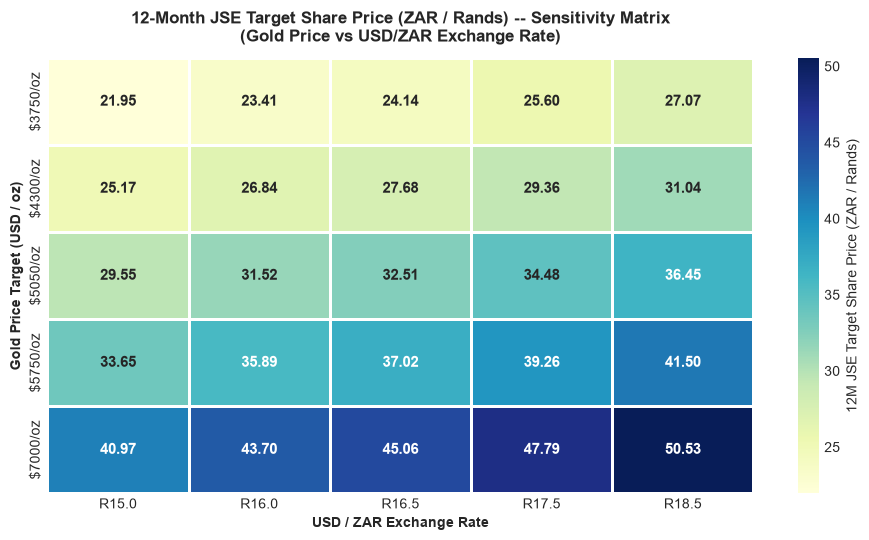

In [7]:
# Enable inline plotting for VS Code
%matplotlib inline

# 2D Sensitivity Grid (Gold Price vs USD/ZAR in ZAR per share)
engine = ValuationEngine(forecast=forecast)
gold_prices = [3750.0, 4300.0, 5050.0, 5750.0, 7000.0]
fx_rates = [15.0, 16.0, 16.5, 17.5, 18.5]
grid = engine.sensitivity_grid(gold_prices=gold_prices, fx_rates=fx_rates, currency='ZAR')

# Format into DataFrame (Rows: Gold Price, Columns: USD/ZAR)
df_grid = pd.DataFrame(grid).T

plt.figure(figsize=(9.5, 5.5))
sns.heatmap(
    df_grid,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    cbar_kws={'label': '12M JSE Target Share Price (ZAR / Rands)'},
    linewidths=1,
    linecolor='white',
    annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
plt.title('12-Month JSE Target Share Price (ZAR / Rands) -- Sensitivity Matrix\n(Gold Price vs USD/ZAR Exchange Rate)', fontweight='bold', pad=12)
plt.xlabel('USD / ZAR Exchange Rate', fontweight='bold')
plt.ylabel('Gold Price Target (USD / oz)', fontweight='bold')
plt.tight_layout()
plt.show()
